## Imports and device configuration

In [1]:
from pathlib import Path

import torch
import pandas as pd
import matplotlib.pyplot as plt

from ultralytics import YOLO

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    DEVICE = 0
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA runtime:", torch.version.cuda)
else:
    DEVICE = "cpu"

print("Training device:", DEVICE)

PyTorch: 2.7.1+cu128
CUDA available: True
GPU: NVIDIA GeForce GTX 1650
CUDA runtime: 12.8
Training device: 0


##  Project paths

In [2]:
PROJECT_DIR = Path.cwd().parent

DATA_YAML = PROJECT_DIR / "dataset" / "processed" / "data.yaml"

OUTPUT_DIR = PROJECT_DIR / "outputs"
RUN_NAME = "yolo11n_bdd100k"
RUN_DIR = OUTPUT_DIR / RUN_NAME
WEIGHTS_DIR = RUN_DIR / "weights"

LAST_CHECKPOINT = WEIGHTS_DIR / "last.pt"
BEST_CHECKPOINT = WEIGHTS_DIR / "best.pt"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert DATA_YAML.exists(), f"Dataset YAML not found: {DATA_YAML}" 

## Checkpoint detection and model initialization

In [3]:
if LAST_CHECKPOINT.exists():
    print("Previous training checkpoint found:")
    print(LAST_CHECKPOINT)
    print("The interrupted training run will be resumed.")

    model = YOLO(str(LAST_CHECKPOINT))
    RESUME_TRAINING = True

else:
    print("No previous checkpoint found.")
    print("Starting fresh from pretrained YOLO11n weights.")

    model = YOLO("yolo11n.pt")
    RESUME_TRAINING = False

print("Resume training:", RESUME_TRAINING)

Previous training checkpoint found:
Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA AUTOPILOT CLONE — OBJECT DETECTION\outputs\yolo11n_bdd100k\weights\last.pt
The interrupted training run will be resumed.
Resume training: True


## Training configuration

In [4]:
IMAGE_SIZE = 512
BATCH_SIZE = 8
WORKERS = 1
FREEZE_LAYERS = 11

TRAIN_ARGS = {
    "data": str(DATA_YAML),
    "epochs": 15,
    "imgsz": IMAGE_SIZE,
    "batch": BATCH_SIZE,
    "workers": WORKERS,
    "device": DEVICE,

    "freeze": FREEZE_LAYERS,

    "optimizer": "auto",
    "weight_decay": 0.0005,

    "amp": True,
    "patience": 4,

    "cache": False,
    "save": True,
    "save_period": -1,
    "val": True,
    "plots": True,

    "project": str(OUTPUT_DIR),
    "name": RUN_NAME,
    "exist_ok": True,

    "seed": 42,
    "deterministic": True,
    "verbose": True
}

pd.Series(TRAIN_ARGS)

data             Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA ...
epochs                                                          15
imgsz                                                          512
batch                                                            8
workers                                                          1
device                                                           0
freeze                                                          11
optimizer                                                     auto
weight_decay                                                0.0005
amp                                                           True
patience                                                         4
cache                                                        False
save                                                          True
save_period                                                     -1
val                                                           

## Training

In [5]:
import time

def gpu_cooldown(trainer):

    time.sleep(90)

    print("Cooldown completed. Continuing training.\n")


model.add_callback("on_fit_epoch_end", gpu_cooldown)

In [7]:
checkpoint = torch.load(
    LAST_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

In [8]:
if RESUME_TRAINING:
    if (checkpoint.get("epoch", -1) + 1) == 15:
        pass
    else:
        results = model.train(resume=True)
else:
    results = model.train(**TRAIN_ARGS)

##  Verify the saved checkpoints



In [10]:
# RUN_DIR = Path(model.trainer.save_dir)
WEIGHTS_DIR = RUN_DIR / "weights"

BEST_CHECKPOINT = WEIGHTS_DIR / "best.pt"
LAST_CHECKPOINT = WEIGHTS_DIR / "last.pt"

print("Training run:", RUN_DIR)
print("best.pt exists:", BEST_CHECKPOINT.exists())
print("last.pt exists:", LAST_CHECKPOINT.exists())

Training run: Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA AUTOPILOT CLONE — OBJECT DETECTION\outputs\yolo11n_bdd100k
best.pt exists: True
last.pt exists: True


## Review training history

In [11]:
RESULTS_CSV = RUN_DIR / "results.csv"

assert RESULTS_CSV.exists(), f"Training history not found: {RESULTS_CSV}"

history = pd.read_csv(RESULTS_CSV)
display(history.tail())

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2,lr/pg3,lr/pg4,lr/pg5,lr/pg6,lr/pg7
10,11,912.531,1.61645,0.97734,0.97088,0.54789,0.28965,0.29391,0.15651,1.51697,0.89844,0.94262,0.015150,0.005050,0.015150,0.005050,0.015150,0.005050,0.015150,0.005050
11,12,916.172,1.60507,0.96856,0.96657,0.55204,0.28876,0.29517,0.15737,1.51544,0.89751,0.94192,0.013665,0.004555,0.013665,0.004555,0.013665,0.004555,0.013665,0.004555
12,13,1007.490,1.59634,0.96116,0.96382,0.55450,0.28928,0.29557,0.15768,1.51465,0.89707,0.94157,0.012180,0.004060,0.012180,0.004060,0.012180,0.004060,0.012180,0.004060
13,14,916.114,1.58889,0.95447,0.96124,0.55701,0.28825,0.29583,0.15787,1.51440,0.89665,0.94124,0.010695,0.003565,0.010695,0.003565,0.010695,0.003565,0.010695,0.003565
14,15,885.260,1.58128,0.94825,0.95906,0.55692,0.28794,0.29589,0.15813,1.51421,0.89641,0.94095,0.009210,0.003070,0.009210,0.003070,0.009210,0.003070,0.009210,0.003070


## Plot training losses and validation metrics

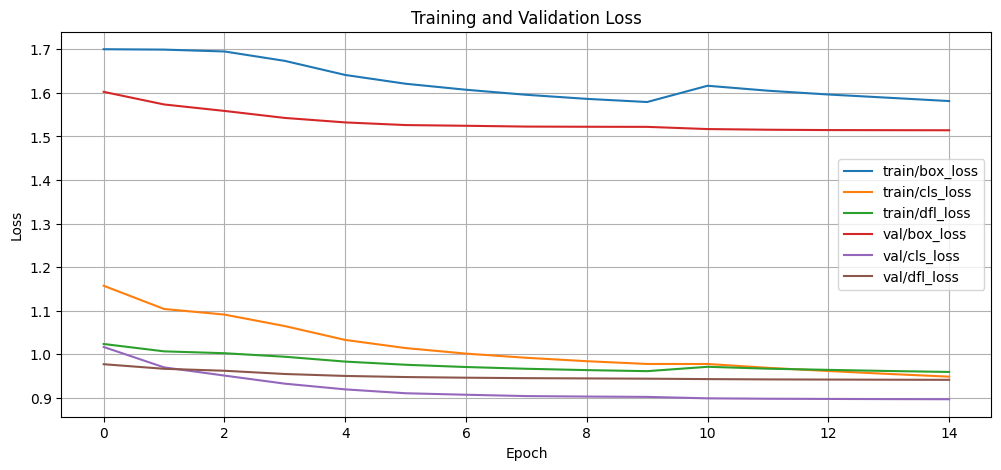

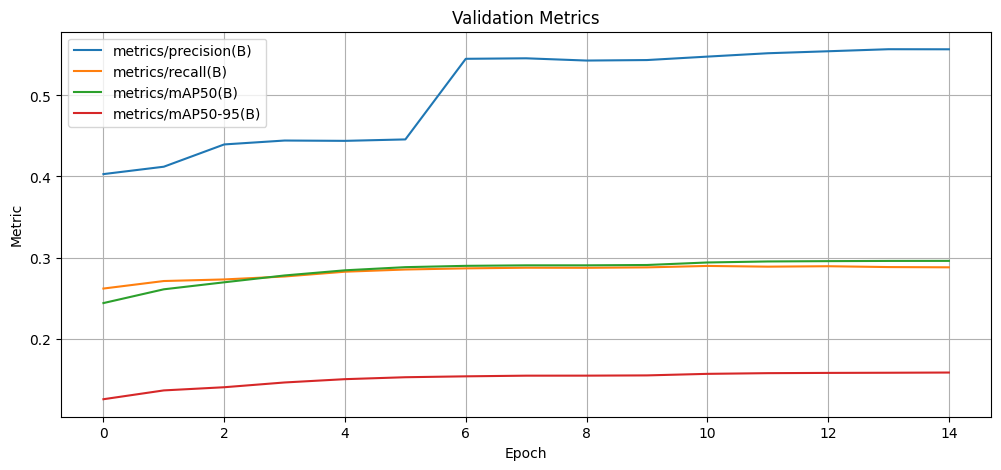

In [12]:
loss_columns = [
    column for column in history.columns
    if "loss" in column.lower()
]

metric_columns = [
    column for column in history.columns
    if any(term in column.lower() for term in ("precision", "recall", "map50", "map"))
]

if loss_columns:
    ax = history[loss_columns].plot(figsize=(12, 5))
    ax.set_title("Training and Validation Loss")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(True)
    plt.show()

if metric_columns:
    ax = history[metric_columns].plot(figsize=(12, 5))
    ax.set_title("Validation Metrics")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Metric")
    ax.grid(True)
    plt.show()

## Load and evaluate the best checkpoint

In [13]:
assert BEST_CHECKPOINT.exists(), "best.pt was not found. Check that training completed at least one validation epoch."

best_model = YOLO(str(BEST_CHECKPOINT))

metrics = best_model.val(
    data=str(DATA_YAML),
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    workers=WORKERS,
    device=DEVICE
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.194  Python-3.10.11 torch-2.7.1+cu128 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
YOLO11n summary (fused): 101 layers, 2,599,238 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.2±0.0 ms, read: 80.8±41.1 MB/s, size: 68.9 KB)
val: Scanning Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA AUTOPILOT CLONE — OBJECT DETECTION\dataset\labels\val.cache... 10000 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10000/10000  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1250/1250 13.9it/s 1:300.1ss
                   all      10000     185526      0.557      0.288      0.296      0.158
                   car       9879     102506       0.59      0.591        0.6       0.35
          traffic sign       8221      34908      0.541      0.333      0.346      0.161
         traffic light       5653      26885      0.437      0.348      0.301     0.0961
                person       3220      13262     

## Per-class evaluation

In [14]:
class_metrics = pd.DataFrame({
    "Class": [best_model.names[index] for index in range(len(best_model.names))],
    "mAP50-95": metrics.box.maps
})

display(
    class_metrics
    .sort_values("mAP50-95", ascending=False)
    .reset_index(drop=True)
)

,Class,mAP50-95
0,car,0.349993
1,bus,0.294931
2,truck,0.282805
3,traffic sign,0.160509
4,person,0.152126
5,traffic light,0.096136
6,rider,0.096005
7,bike,0.076855
8,motor,0.072268
9,train,0.000000


## Run inference on a validation image

Set `IMAGE_PATH` to an existing validation image. This cell is optional.

In [15]:
IMAGE_PATH = r"Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA AUTOPILOT CLONE — OBJECT DETECTION\dataset\images\val\b2e54795-d8c2ba6d.jpg"

if IMAGE_PATH is not None:
    predictions = best_model.predict(
        source=str(IMAGE_PATH),
        conf=0.25,
        imgsz=IMAGE_SIZE,
        device=DEVICE,
        save=True
    )
    display(predictions[0].plot())
else:
    print("Set IMAGE_PATH to a validation image to run inference.")


image 1/1 Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA AUTOPILOT CLONE — OBJECT DETECTION\dataset\images\val\b2e54795-d8c2ba6d.jpg: 288x512 3 cars, 4 traffic lights, 1 bus, 38.5ms
Speed: 10.8ms preprocess, 38.5ms inference, 6.2ms postprocess per image at shape (1, 3, 288, 512)
Results saved to Y:\Python\AI ML\Month 2\week 8-NLP\50 — TESLA AUTOPILOT CLONE — OBJECT DETECTION\notebooks\runs\detect\predict-2


array([[[194, 146,  88],
        [194, 146,  88],
        [194, 146,  88],
        ...,
        [219, 177, 118],
        [219, 177, 118],
        [219, 177, 118]],

       [[194, 146,  88],
        [194, 146,  88],
        [194, 146,  88],
        ...,
        [219, 177, 118],
        [219, 177, 118],
        [219, 177, 118]],

       [[194, 146,  88],
        [194, 146,  88],
        [194, 146,  88],
        ...,
        [219, 177, 118],
        [219, 177, 118],
        [219, 177, 118]],

       ...,

       [[ 90, 133, 152],
        [ 90, 133, 152],
        [ 90, 133, 152],
        ...,
        [ 10,   7,   3],
        [ 10,   7,   3],
        [ 10,   7,   3]],

       [[ 95, 141, 158],
        [ 95, 141, 158],
        [ 94, 140, 157],
        ...,
        [ 10,   7,   3],
        [ 10,   7,   3],
        [ 10,   7,   3]],

       [[ 91, 140, 156],
        [ 91, 140, 156],
        [ 91, 140, 156],
        ...,
        [ 10,   7,   3],
        [ 10,   7,   3],
        [ 10,   7,   3]]